<a href="https://colab.research.google.com/github/ezgitemur/GROUP18_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1: Exploratory Data Analysis and Baseline Models

**Competition:** CMI – Detect Behavior with Sensor Data (Kaggle)  
**Task:** Classify 18 gestures (8 BFRB, 10 non-BFRB) from wrist-worn sensor data (IMU, thermopile, ToF).

## 1. Data Download
**Purpose:** Download the competition data using the Kaggle API. Credentials are stored in Colab Secrets and are not included in this notebook.

In [1]:
import os
from google.colab import userdata

# Secrets'tan anahtarları oku
os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

# Veriyi indir ve zip'ten çıkar
!kaggle competitions download -c cmi-detect-behavior-with-sensor-data -p data
!unzip -q data/cmi-detect-behavior-with-sensor-data.zip -d data
!ls -lh data

100% 178M/178M [00:02<00:00, 75.6MB/s]

total 1.3G
-rw-r--r-- 1 root root 178M May 30  2025 cmi-detect-behavior-with-sensor-data.zip
drwxr-xr-x 3 root root 4.0K Nov  9 09:20 kaggle_evaluation
-rw-r--r-- 1 root root 199K May 30  2025 test.csv
-rw-r--r-- 1 root root  158 May 30  2025 test_demographics.csv
-rw-r--r-- 1 root root 1.1G May 30  2025 train.csv
-rw-r--r-- 1 root root 2.9K May 30  2025 train_demographics.csv


**Findings:** The archive (178 MB) contains `train.csv` (1.1 GB), `train_demographics.csv`, and small sample test files. The real test set is hidden and only used during Kaggle submission.

## 2. Loading the Data
**Purpose:** Load the training data and inspect its size and first rows.

In [2]:
import pandas as pd

train = pd.read_csv("data/train.csv")
print(train.shape)
train.head()

(574945, 341)


,row_id,sequence_type,sequence_id,sequence_counter,subject,orientation,behavior,phase,gesture,acc_x,...,tof_5_v54,tof_5_v55,tof_5_v56,tof_5_v57,tof_5_v58,tof_5_v59,tof_5_v60,tof_5_v61,tof_5_v62,tof_5_v63
0,SEQ_000007_000000,Target,SEQ_000007,0,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,6.683594,...,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
1,SEQ_000007_000001,Target,SEQ_000007,1,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,6.949219,...,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
2,SEQ_000007_000002,Target,SEQ_000007,2,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,5.722656,...,-1.0,-1.0,112.0,119.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
3,SEQ_000007_000003,Target,SEQ_000007,3,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,6.601562,...,-1.0,-1.0,101.0,111.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
4,SEQ_000007_000004,Target,SEQ_000007,4,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,5.566406,...,-1.0,-1.0,101.0,109.0,125.0,-1.0,-1.0,-1.0,-1.0,-1.0


**Findings:** The training set has 574,945 rows and 341 columns. Each row is one time step, and rows are grouped into recordings by `sequence_id`. The target label is `gesture`.

## 3. Column Overview
**Purpose:** List the columns and group them by type.

In [3]:
print(train.columns[:20].tolist())
print("...")
print(train.columns[-5:].tolist())

['row_id', 'sequence_type', 'sequence_id', 'sequence_counter', 'subject', 'orientation', 'behavior', 'phase', 'gesture', 'acc_x', 'acc_y', 'acc_z', 'rot_w', 'rot_x', 'rot_y', 'rot_z', 'thm_1', 'thm_2', 'thm_3', 'thm_4']
...
['tof_5_v59', 'tof_5_v60', 'tof_5_v61', 'tof_5_v62', 'tof_5_v63']


**Findings:** 9 metadata columns, 7 IMU columns (`acc_x/y/z` acceleration, `rot_w/x/y/z` orientation quaternion), 5 thermopile columns (`thm_1`–`thm_5`), and 320 ToF columns (5 sensors × 8×8 pixels, `tof_1_v0`–`tof_5_v63`).

## 4. Sequences and Subjects
**Purpose:** Count the number of recordings and participants.

In [4]:
print("Sequence sayısı:", train["sequence_id"].nunique())
print("Kişi sayısı:", train["subject"].nunique())

Sequence sayısı: 8151
Kişi sayısı: 81


**Findings:** 8,151 sequences from 81 subjects (about 100 sequences per subject). Since the hidden test set contains unseen subjects, validation must split data by subject (e.g. `GroupKFold`).

## 5. Gesture Distribution
**Purpose:** Count sequences per gesture to check class balance.

In [5]:
seq_gesture = train.groupby("sequence_id")["gesture"].first()
seq_gesture.value_counts()

,count
gesture,
Forehead - pull hairline,640
Neck - pinch skin,640
Text on phone,640
Neck - scratch,640
Forehead - scratch,640
Eyelash - pull hair,640
Above ear - pull hair,638
Eyebrow - pull hair,638
Cheek - pinch skin,637


**Findings:** 18 gestures. The 8 BFRB gestures are balanced (~640 each), while the 10 non-BFRB gestures are imbalanced (161–640). "Pinch knee/leg skin" and "Scratch knee/leg skin" involve the same motion as some BFRBs but at a different body location, so proximity (ToF) and thermal sensors may be important to tell them apart.

## 6. Target vs Non-Target
**Purpose:** Check the ratio of BFRB (Target) to non-BFRB (Non-Target) sequences.

In [6]:
seq_type = train.groupby("sequence_id")["sequence_type"].first()
seq_type.value_counts()

,count
sequence_type,
Target,5113
Non-Target,3038


**Findings:** 5,113 Target (63%) and 3,038 Non-Target (37%) sequences.

## 7. Sequence Lengths
**Purpose:** Examine how many time steps each sequence contains.

In [7]:
seq_len = train.groupby("sequence_id").size()
seq_len.describe()

,0
count,8151.000000
mean,70.536744
std,35.389879
min,29.000000
25%,51.000000
50%,59.000000
75%,78.000000
max,700.000000


**Findings:** Mean length is 70.5 and median is 59 time steps, with a minimum of 29 and a maximum of 700. The distribution is right-skewed with a few very long outliers, so models that need fixed-length input will require padding or truncation.

## 8. Gesture Distribution (Plot)
**Purpose:** Visualize the number of sequences per gesture, colored by BFRB (Target) and non-BFRB (Non-Target).

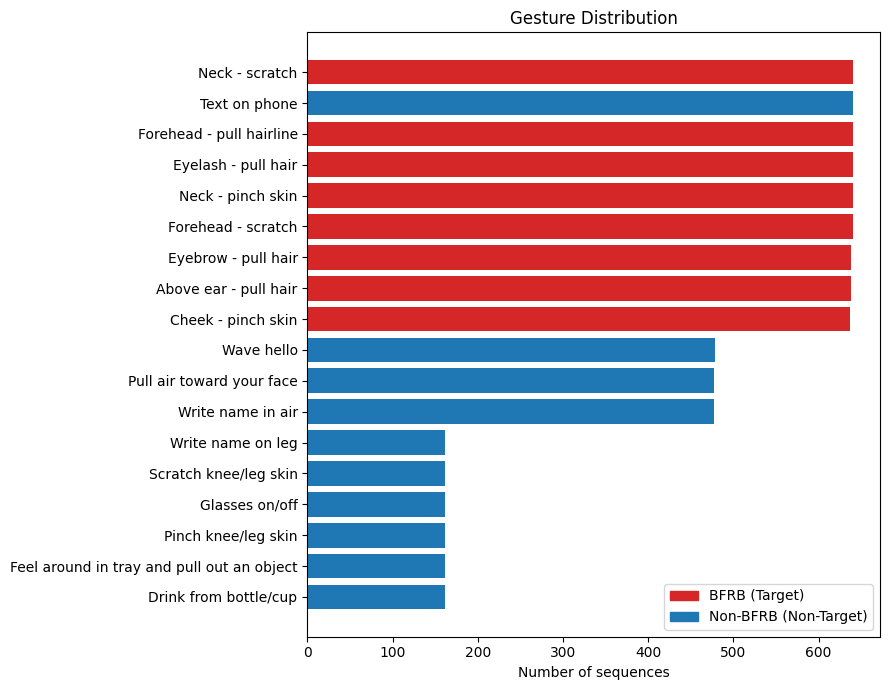

In [8]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

seq_info = train.groupby("sequence_id")[["gesture", "sequence_type"]].first()
counts = (seq_info.groupby(["gesture", "sequence_type"]).size()
          .reset_index(name="count").sort_values("count"))

colors = counts["sequence_type"].map({"Target": "tab:red", "Non-Target": "tab:blue"})

plt.figure(figsize=(9, 7))
plt.barh(counts["gesture"], counts["count"], color=colors)
plt.xlabel("Number of sequences")
plt.title("Gesture Distribution")
plt.legend(handles=[Patch(color="tab:red", label="BFRB (Target)"),
                    Patch(color="tab:blue", label="Non-BFRB (Non-Target)")])
plt.tight_layout()
plt.show()

**Findings:** The gestures form three groups by frequency: the 8 BFRB gestures and "Text on phone" (about 640 sequences each), three non-BFRB gestures (about 477 each), and six non-BFRB gestures (161 each). BFRB classes are balanced, while non-BFRB classes are imbalanced by a factor of about 4. Since the competition metric merges all non-BFRB gestures into a single class, this imbalance has a limited effect on the score.

## 9. Sequence Length Distribution (Plot)
**Purpose:** Visualize the distribution of sequence lengths to identify skewness and outliers.

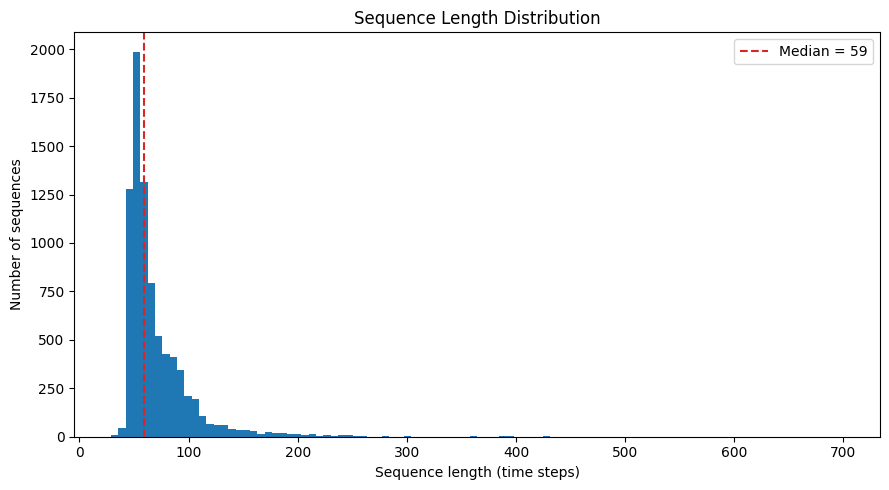

In [9]:
plt.figure(figsize=(9, 5))
plt.hist(seq_len, bins=100, color="tab:blue")
plt.axvline(seq_len.median(), color="tab:red", linestyle="--",
            label=f"Median = {seq_len.median():.0f}")
plt.xlabel("Sequence length (time steps)")
plt.ylabel("Number of sequences")
plt.title("Sequence Length Distribution")
plt.legend()
plt.tight_layout()
plt.show()

**Findings:** Most sequences are between 40 and 120 time steps long, with a peak around 50–60. The distribution has a long right tail: sequences longer than 200 steps are rare, and the longest (700 steps) is an extreme outlier. For models that require fixed-length input, a length around the 90th–95th percentile could be used, padding shorter sequences and truncating longer ones.

## 10. Missing Values
**Purpose:** Measure the percentage of missing values in each sensor group (IMU, thermopile, ToF).

In [10]:
imu_cols = [c for c in train.columns if c.startswith(("acc_", "rot_"))]
thm_cols = [c for c in train.columns if c.startswith("thm_")]
tof_cols = [c for c in train.columns if c.startswith("tof_")]

sensor_groups = {"IMU": imu_cols, "Thermopile": thm_cols, "ToF": tof_cols}

for name, cols in sensor_groups.items():
    missing = train[cols].isna().mean().mean() * 100
    print(f"{name}: {len(cols)} columns, {missing:.2f}% missing")

IMU: 7 columns, 0.37% missing
Thermopile: 5 columns, 2.11% missing
ToF: 320 columns, 1.91% missing


**Findings:** Missing values (NaN) are rare in the training data: 0.37% for IMU, 2.11% for thermopile, and 1.91% for ToF. Note that about half of the hidden test set contains only IMU data, so the model must also work without thermopile and ToF sensors. In addition, ToF sensors record -1 when no object is detected, which is not counted as NaN and is examined separately below.

## 11. ToF "No Detection" Values
**Purpose:** Measure how often ToF pixels report -1 (no object detected).

In [11]:
tof_values = train[tof_cols]
no_detection = (tof_values == -1).mean().mean() * 100
print(f"ToF pixels with -1 (no detection): {no_detection:.2f}%")

print("\nBy sequence type:")
for seq_t in ["Target", "Non-Target"]:
    rows = train["sequence_type"] == seq_t
    pct = (tof_values[rows] == -1).mean().mean() * 100
    print(f"  {seq_t}: {pct:.2f}%")

ToF pixels with -1 (no detection): 57.49%

By sequence type:
  Target: 50.72%
  Non-Target: 67.57%


**Findings:** 57.49% of ToF pixel values are -1 (no object detected), which is far more common than NaN. The rate is lower in BFRB sequences (50.72%) than in non-BFRB sequences (67.57%), suggesting that ToF sensors detect nearby objects (e.g. the face or head) more often during BFRBs. Therefore, -1 values carry information and should not be treated as simple missing data.